# Conciliación de facturas de transportistas

Este cuaderno muestra, paso a paso, qué hace la herramienta: lee las facturas de los transportistas, las compara con el registro de cargas acordadas y lista lo que una persona debe revisar, con la razón.

**Cómo usarlo:** en el menú elija `Runtime > Run all` (en español: Entorno de ejecución > Ejecutar todo) y espere. Tarda entre 1 y 2 minutos. No necesita ninguna clave ni escribir nada.

La herramienta no aprueba ni paga facturas: solo avisa qué conviene revisar.

## Paso 1. Descargar el proyecto

Se descarga la versión entregada del proyecto (etiqueta `entrega-v1`) y se instalan los programas de apoyo. Pueden aparecer varias líneas de texto. Si aparece un mensaje en rojo que empieza con "ERROR: pip's dependency resolver", es un aviso de compatibilidad con un programa propio de Colab. No afecta esta demostración.

In [1]:
!rm -rf freight-invoice-recon
!git clone --depth 1 --branch entrega-v1 https://github.com/yarecast/freight-invoice-recon.git
%cd freight-invoice-recon
!pip install -q -r requirements.txt

Cloning into 'freight-invoice-recon'...
remote: Enumerating objects: 88, done.
remote: Counting objects: 100% (88/88), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 88 (delta 18), reused 79 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (88/88), 1.20 MiB | 7.28 MiB/s, done.
Resolving deltas: 100% (18/18), done.
Note: switching to '0186a64c59f50adc79f2ba3d070a016c4db95720'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

/content/freight-invoice-recon
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## Paso 2. Ejecutar la herramienta

Lee las 18 facturas, las compara con el registro de cargas y genera el reporte. Este modo no usa internet ni claves: usa las lecturas que ya se guardaron en la carpeta `extractions/`.

In [2]:
!python run.py

Reporte generado en modo demo: 18 facturas.
  ALTA: 9 | MEDIA: 1 | BAJA: 1 | NADA QUE REVISAR: 7
  Cargas sin factura (informativo): 2
  output/reporte.html
  output/reporte.csv


## Paso 3. El reporte

Esta es la lista de lo que una persona debe revisar. Empiece por la tabla "Excepciones por severidad": cada fila trae la razón y la acción sugerida.

In [3]:
from IPython.display import HTML, display

with open("output/reporte.html", encoding="utf-8") as fh:
    display(HTML(fh.read()))

## Paso 4. Una factura y lo que la herramienta leyó

A la izquierda, la factura 17, que tiene notas escritas a mano. A la derecha, los datos que el modelo leyó de ella, cada uno con el texto de la factura que lo respalda. El reporte marca esta factura para revisión porque el total escrito a mano no coincide con lo pactado.

,"{ ""source_file"": ""factura_17_riogrande_RG-7812.pdf"", ""source_sha256"": ""f9e0073f138a9654d4ff83338e76d5c8be9efa631b3d381341bd768c5548e3de"", ""extracted_at"": ""2026-10-11T17:06:21+00:00"", ""model"": ""gemini-3.8-flash"", ""prompt_version"": ""v1"", ""carrier"": { ""value"": ""RIO GRANDE FREIGHT LINES"", ""evidence"": ""RIO GRANDE FREIGHT LINES"" }, ""invoice_number"": { ""value"": ""RG-7812"", ""evidence"": ""Invoice #: RG-7812"" }, ""load_ref"": { ""value"": ""TRQ-4487"", ""evidence"": ""LOAD #\n\nTRQ-4487"" }, ""invoice_date"": { ""value"": ""2026-09-26"", ""evidence"": ""Date: September 26, 2026"" }, ""amount_printed"": { ""value"": ""850.00"", ""evidence"": ""TOTAL DUE $850.00 USD"" }, ""currency"": { ""value"": ""USD"", ""evidence"": ""$850.00 USD"" }, ""handwritten_annotations"": [ { ""text"": ""+ 150 detention"", ""amounts"": [ ""150"" ] }, { ""text"": ""TOTAL 1,000"", ""amounts"": [ ""1,000"" ] } ], ""document_type"": ""INVOICE"", ""legibility_notes"": null }"

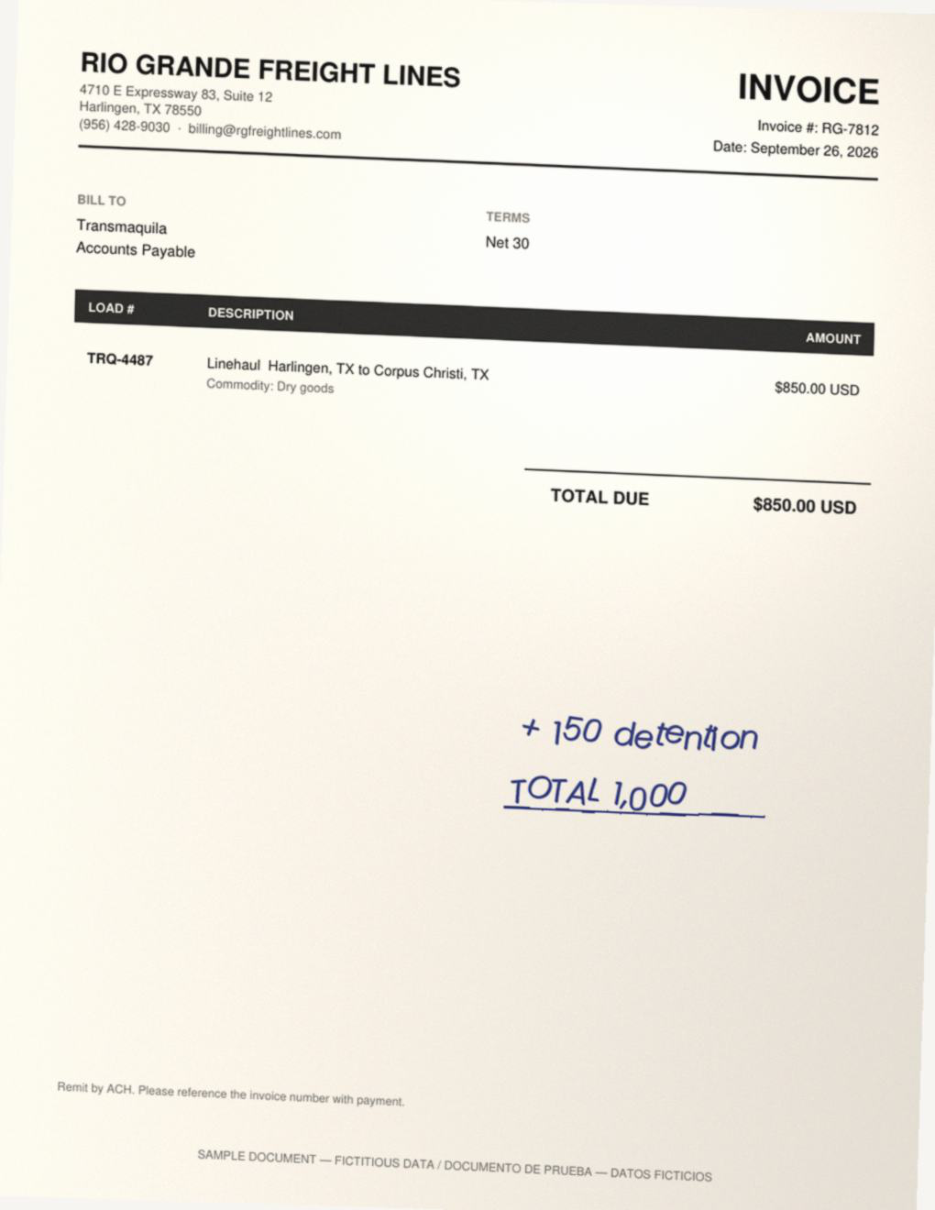

In [4]:
import base64, html, json
from pathlib import Path

import pymupdf
from IPython.display import HTML, display

pdf_path = next(Path("data/facturas").glob("factura_17*.pdf"))
json_path = Path("extractions") / (pdf_path.stem + ".json")

with pymupdf.open(pdf_path) as doc:
    png = doc[0].get_pixmap(dpi=110).tobytes("png")
image = base64.b64encode(png).decode("ascii")

data = json.loads(json_path.read_text(encoding="utf-8"))
pretty = html.escape(json.dumps(data, indent=2, ensure_ascii=False))

display(HTML(
    "<table><tr>"
    f'<td style="vertical-align:top;width:50%"><img src="data:image/png;base64,{image}" style="max-width:100%"></td>'
    f'<td style="vertical-align:top"><pre style="font-size:12px;white-space:pre-wrap">{pretty}</pre></td>'
    "</tr></table>"
))

## Opcional. Ejecutar con el modelo en vivo

No es necesario para ver el resultado. Esta celda está comentada. Para usarla, guarde su propia clave en `Secrets` (icono de llave a la izquierda) con los nombres `GEMINI_API_KEY` y `GEMINI_MODEL`, quite el `#` de cada línea y ejecútela. Nunca escriba la clave dentro del cuaderno.

In [5]:
# import os
# from google.colab import userdata
#
# os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
# os.environ["GEMINI_MODEL"] = userdata.get("GEMINI_MODEL")
# !python run.py --live --only-missing